In [46]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression

In [47]:
X,y = make_classification (n_samples=1000,
                          n_features=2,
                          n_informative=2,
                          n_redundant=0,
                          n_classes=2,
                          class_sep=2,
                          random_state=1)

In [48]:
pd.DataFrame(X).head()

,0,1
0,1.863411,0.087646
1,-1.530997,1.901182
2,-0.017224,-2.591112
3,-2.032039,-1.801162
4,4.620555,0.901124


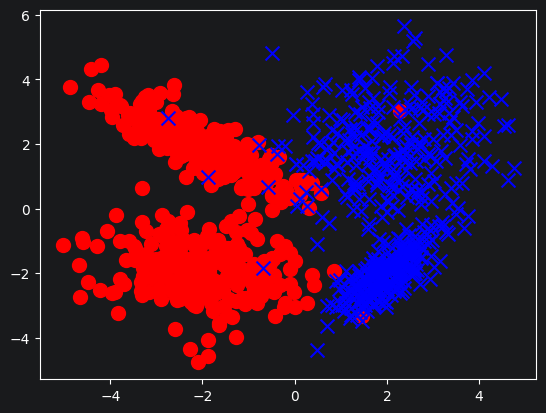

In [49]:
plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)
plt.show()

In [50]:
class SGD():
    def __init__(self, alpha=0.5, n_iters=1000):
        self.b = None
        self._alpha = alpha
        self._n_iters = n_iters
    def gradient_step(self, b, b_grad):
        return b - self._alpha * b_grad
    def optimize(self, X, y, start_b, n_iters):
        b = start_b.copy()
        for i in range(n_iters):
            b_grad = self.grad_func(X, y, b)
            b = self.gradient_step(b, b_grad)
        return b
    def fit(self, X, y):
        m = X.shape[1]
        start_b = np.ones(m)
        self.b = self.optimize(X, y, start_b, self._n_iters)


In [51]:
class LogReg(SGD):
    def sigmoid(self, X, b):
        return 1. / (1. + np.exp(-X.dot(b)))
    def grad_func(self, X, y, b):
        n = X.shape[0]
        grad = 1. / n * X.transpose().dot(self.sigmoid(X, b) - y)
        return grad
    def predict_proba(self, X):
        return self.sigmoid(X, self.b)
    def predict(self, X):
        y_pred = self.predict_proba(X) > 0.5
        return y_pred

In [52]:
logreg = LogReg()
X = np.hstack([np.ones(X.shape[0])[:, np.newaxis], X])
logreg.fit(X, y)
y_pred = logreg.predict(X)

In [53]:
ac = accuracy_score(y, y_pred)
f1 = f1_score(y, y_pred)
print(f'accuracy = {ac:.2f} F1-score = {f1:.2f}')

accuracy = 0.98 F1-score = 0.98


In [54]:
y_pred_proba = logreg.predict_proba(X)

In [55]:
xx, yy = np.meshgrid(
    np.arange(X.min(axis=0)[1]-1, X.max(axis=0)[1]+1, 0.01),
    np.arange(X.min(axis=0)[2]-1, X.max(axis=0)[2]+1, 0.01))
XX = np.array(list(zip(xx.ravel(), yy.ravel()))).reshape((-1, 2))
XX = np.array([(1, *xx) for xx in XX])

In [56]:
Z = logreg.predict_proba(XX)
Z = Z.reshape(xx.shape)

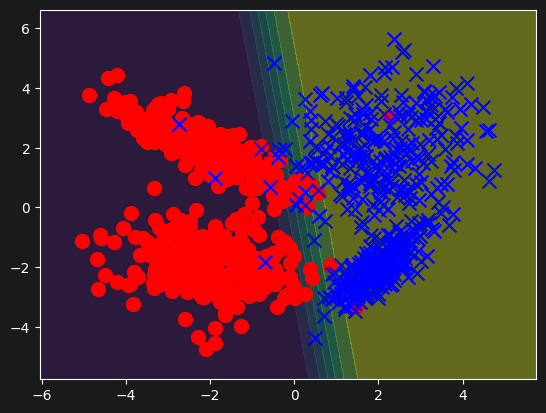

In [57]:
plt.contourf(xx, yy, Z, alpha=0.4)
plt.scatter(X[:, 1][y==0], X[:, 2][y==0], marker="o", c='r', s=100)
plt.scatter(X[:, 1][y==1], X[:, 2][y==1], marker="x", c='b', s=100)

In [74]:
X,y = make_classification (n_samples=1000,
                          n_features=2,
                          n_informative=2,
                          n_redundant=0,
                          n_classes=2,
                          class_sep=2,
                          random_state=1)

In [75]:
model = LogisticRegression()
model.fit(X, y)
y_pred_lr = model.predict(X)
y_pred_proba_lr = model.predict_proba(X)

In [76]:
ac = accuracy_score(y, y_pred_lr)
f1 = f1_score(y, y_pred_lr)
print(f'accuracy = {ac:.2f} F1-score = {f1:.2f}')

accuracy = 0.98 F1-score = 0.98


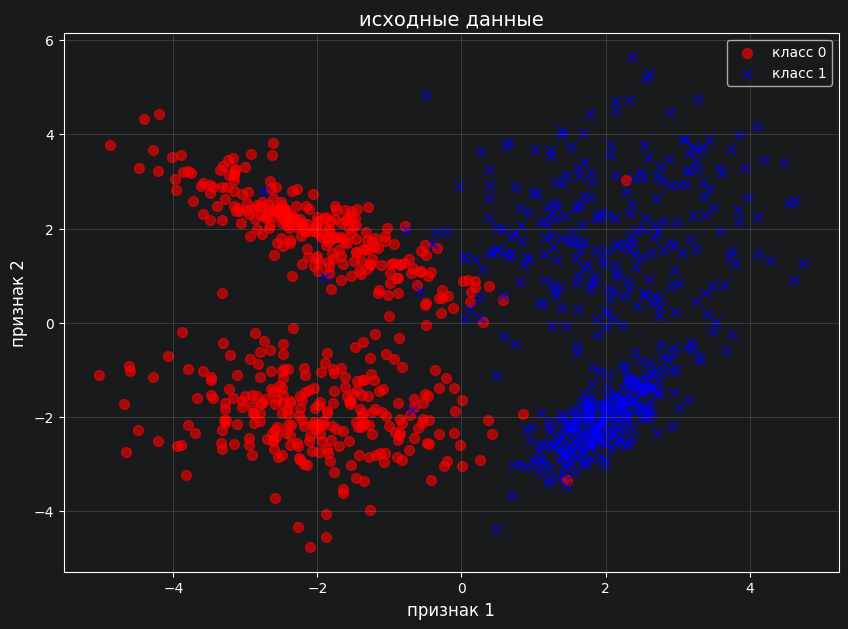

In [77]:
plt.figure(figsize=(10, 7))

plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='red', s=50,
            label='класс 0', alpha=0.6)
plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='blue', s=50,
            label='класс 1', alpha=0.6)

plt.xlabel('признак 1', fontsize=12)
plt.ylabel('признак 2', fontsize=12)
plt.title('исходные данные', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)

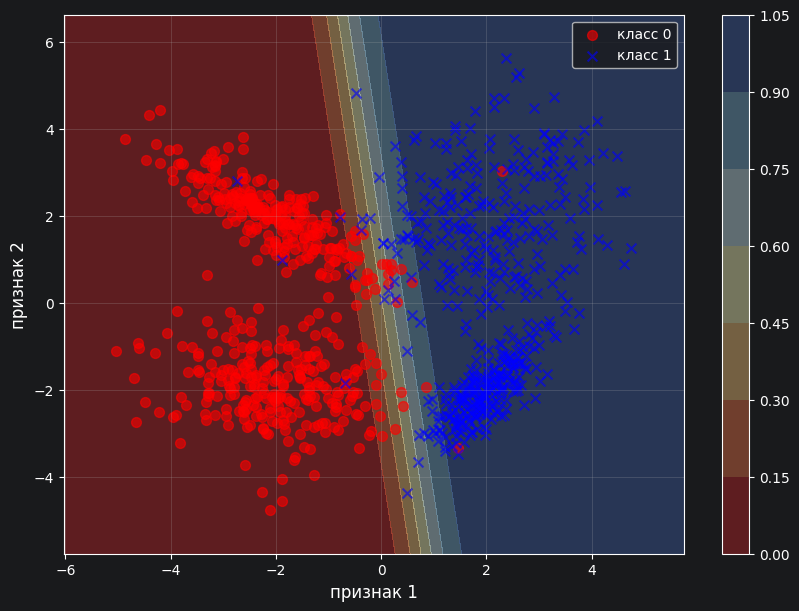

In [79]:
plt.figure(figsize=(10, 7))

xx, yy = np.meshgrid(
    np.arange(X[:, 0].min()-1, X[:, 0].max()+1, 0.01),
    np.arange(X[:, 1].min()-1, X[:, 1].max()+1, 0.01)
)
XX = np.c_[xx.ravel(), yy.ravel()]
Z = model.predict_proba(XX)[:, 1]
Z = Z.reshape(xx.shape)

contour = plt.contourf(xx, yy, Z, alpha=0.4, cmap='RdYlBu')

plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='red', s=50,
            label='класс 0', alpha=0.6)
plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='blue', s=50,
            label='класс 1', alpha=0.6)

plt.xlabel('признак 1', fontsize=12)
plt.ylabel('признак 2', fontsize=12)
plt.legend()
plt.colorbar(contour)
plt.grid(True, alpha=0.3)

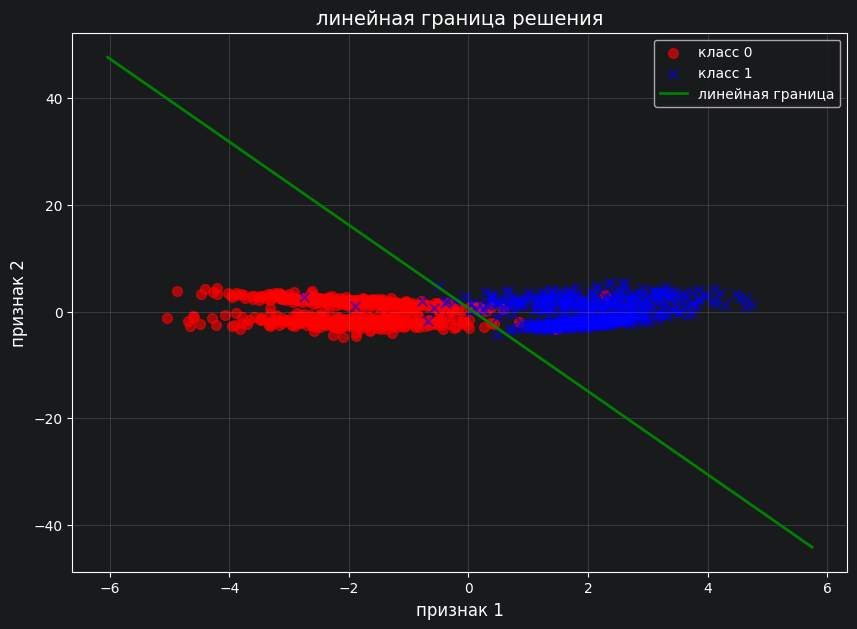

In [80]:
plt.figure(figsize=(10, 7))

x_line = np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, 100)
w1, w2 = model.coef_[0]
b = model.intercept_[0]
y_line = -(w1 * x_line + b) / w2

plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='red', s=50,
            label='класс 0', alpha=0.6)
plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='blue', s=50,
            label='класс 1', alpha=0.6)
plt.plot(x_line, y_line, 'g-', linewidth=2, label='линейная граница')

plt.xlabel('признак 1', fontsize=12)
plt.ylabel('признак 2', fontsize=12)
plt.title('линейная граница решения', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
